# RideOps | Report-export triage
Run all cells to replay intake, inspect a draft, and measure historical search coverage.

In [1]:
from pathlib import Path
import sys, io, zipfile
root = Path.cwd()
if not (root / 'triage.py').is_file():
    from google.colab import files
    uploaded = files.upload()
    archives = [data for name,data in uploaded.items() if name.lower().endswith('.zip')]
    if len(archives) != 1:
        raise ValueError('Select the project ZIP and optionally practice_timings.csv together.')
    root = Path('/content/rideops_agent')
    root.mkdir(parents=True,exist_ok=True)
    timings = root / 'practice_timings.csv'
    timings.unlink(missing_ok=True)
    for name,data in uploaded.items():
        if name.lower().endswith('.csv'):
            timings.write_bytes(data)
    with zipfile.ZipFile(io.BytesIO(archives[0])) as z:
        for name in ['triage.py','data/rideops_support_tickets.csv']:
            dest = root / name
            dest.parent.mkdir(parents=True,exist_ok=True)
            dest.write_bytes(z.read('RideOps_Agent/' + name))
sys.path.insert(0,str(root))
from triage import load,reports,candidates,draft,evaluate
import pandas as pd
import matplotlib.pyplot as plt
d=load()
r=reports(d)
print(f'{len(d)} support tickets, including {len(r)} report-export tickets.')

1444 support tickets, including 206 report-export tickets.


## Backlog and opportunity
Month-end counts use final closure. Intermediate reopen times are unavailable.

In [2]:
incoming=d.groupby(d.created_at.dt.month).size()
closed=d.groupby(d.final_closed_at.dt.month).size()
display(pd.DataFrame({'Raised':incoming,'Finally closed':closed,'Backlog':(incoming-closed).cumsum()}))
display(r.eng_outcome.value_counts().rename('Escalation outcomes').to_frame())

,Raised,Finally closed,Backlog
7,390,360,30
8,462,469,23
9,592,567,48


,Escalation outcomes
eng_outcome,
Duplicate of known issue,30
Fixed,26
Config issue - returned to L1,9
Insufficient info - returned to L1,9
Not a bug - how-to,2
Not reproducible,1


## Arrival-time demo
The helper searches earlier tickets with the same symptom, prioritizing the same client and then recency. Final outcomes and engineering references appear only after final closure.

In [3]:
case=r.loc['SUP-10031']
display(candidates(r,case)[['description','created_at','Known outcome','Engineering reference']])
print('Initial draft:',draft(case)[0])
print('After example reply:',draft(case,'1 July to 3 July, at 10:30')[0])

,description,created_at,Known outcome,Engineering reference
ticket_id,,,,
SUP-10030,Monthly trip report download stuck at loading,2026-07-03 22:22:00,Unavailable at arrival,—
SUP-10020,Monthly trip report download stuck at loading,2026-07-03 08:10:00,Unavailable at arrival,—


Initial draft: Thanks for reporting this. Which start and end dates did you select? Around what time did this happen?
After example reply: Thanks for the details. We’ll use them to investigate the report issue and follow up here.


## September replay
September is a descriptive replay. The five symptom rules were designed after inspecting this synthetic dataset. The export descriptions repeat heavily.

,sum,count
Other or unlabeled,74,74
Later labeled duplicate,16,16


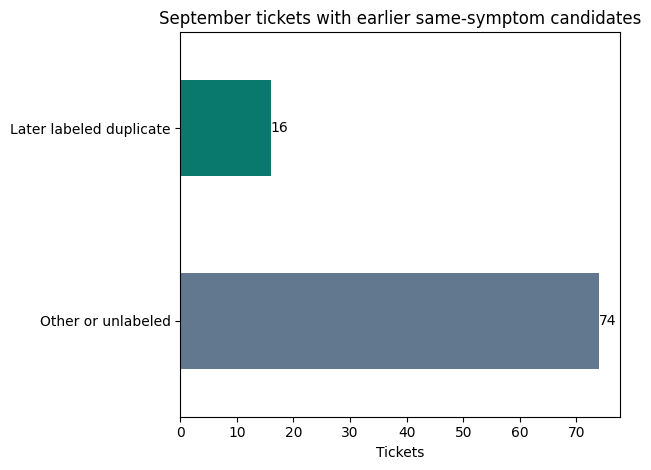

In [4]:
results=evaluate(r)
sep=results[results.created_at.ge('2026-09-01')].copy()
sep['hit']=sep.candidate_count.gt(0)
summary=sep.groupby('later_duplicate').hit.agg(['sum','count'])
summary.index=['Other or unlabeled','Later labeled duplicate']
display(summary)
ax=summary['sum'].plot.barh(color=['#62788f','#08796c'],title='September tickets with earlier same-symptom candidates')
ax.set_xlabel('Tickets')
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

All 90 September reports had a candidate, including all 16 later labeled duplicate. Coverage is high in both groups. Candidate presence alone cannot distinguish duplicates. Original incident IDs and handling-time trials are unavailable.

## Observed practice time
Complete paired trials in the app. Upload the exported CSV with the ZIP. Inspect replies for comparable quality. Positive values mean the assisted task was faster. These timings measure first-reply preparation.

In [ ]:
timing_file = root / 'practice_timings.csv'
if timing_file.exists():
    trials = pd.read_csv(timing_file)
    display(trials[['mode','ticket','seconds','reply','reference']])
    paired = trials.pivot(index='pair',columns='mode',values='seconds').reindex(columns=['Manual','Assisted']).dropna()
    if len(paired):
        paired['Saved seconds'] = paired.Manual - paired.Assisted
        display(paired)
        print(f'{len(paired)} completed pairs. Median saving: {paired["Saved seconds"].median():.1f} seconds.')
        paired[['Manual','Assisted']].median().plot.bar(ylabel='Median practice seconds',rot=0)
        plt.show()
    else:
        print('Finish both tasks in a pair and export again.')
else:
    print('To measure handling time, complete a pair in Timed practice and upload its CSV with the project ZIP.')